# Lab 02 · NumPy for Numerical Computing
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 5** (C-3 Apply, PLO 5 Modern Tool Usage): *Use Python programming and tools to perform data handling and basic operations.*

**Rules:** no Python loops where a NumPy function exists · label every output, e.g. `print("T6b:", ...)` · Runtime → Restart and run all before you submit · push to `ML-Lab-<RollNo>/Lab02/Lab02.ipynb` by **Thursday 29 Oct, 11:59 PM**.

**Name:** Syeda Khadija Hassan  ·  **Roll No:** 2024-SE-09  
**Department:** Software Engineering, University of Azad Jammu & Kashmir, Muzaffarabad

### Datasets (run this cell first, do not edit)
- **Census 2023**: Pakistan Bureau of Statistics, 7th Population and Housing Census (provinces, ICT, AJK, GB).
- **Climate**: 1991–2020 climate normals (PMD / WMO) as published in the city climate tables.
- **Inflation**: Pakistan Economic Survey 2024-25, Chapter 7, Fig 7.1 (PBS CPI, year-on-year %).
- **Marks**: sample lab-section marks.

In [1]:
import numpy as np

# ===================== DATASETS (given to students in the starter notebook) =====================
# D1. Population Census 2023 (PBS), source: 2023 Pakistani census results
units = np.array(["Punjab", "Sindh", "Khyber Pakhtunkhwa", "Balochistan", "Islamabad", "AJK", "Gilgit-Baltistan"])
pop_2023 = np.array([127_688_922, 55_696_147, 40_856_097, 14_894_402, 2_363_863, 4_333_467, 1_709_049])
pop_2017 = np.array([109_989_655, 47_854_510, 35_501_964, 12_335_129, 2_003_368, 4_045_367, 1_492_924])

# D2. Climate normals 1991-2020 (PMD / WMO), mean daily maximum temperature (°C) and rainfall (mm)
cities = np.array(["Lahore", "Karachi", "Islamabad", "Peshawar", "Quetta"])
months = np.array(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
tmax = np.array([
    [18.4, 22.2, 27.5, 34.2, 38.9, 38.9, 35.6, 34.7, 34.4, 32.4, 27.1, 21.4],   # Lahore
    [26.3, 28.7, 32.6, 35.0, 35.7, 35.7, 33.6, 32.5, 33.4, 35.6, 32.6, 28.4],   # Karachi
    [17.7, 20.0, 24.8, 30.6, 36.1, 38.3, 35.4, 33.9, 33.4, 30.9, 25.4, 20.4],   # Islamabad
    [18.1, 20.1, 24.7, 30.6, 36.5, 39.6, 37.4, 35.9, 34.8, 31.0, 25.2, 20.6],   # Peshawar
    [11.8, 14.0, 19.5, 25.9, 31.4, 35.5, 36.8, 35.4, 31.9, 26.0, 19.6, 14.6]])  # Quetta
rain = np.array([
    [21.9, 31.5, 31.5, 19.5, 17.7, 73.8, 188.6, 177.1, 88.6, 10.3, 6.9, 6.8],
    [10.6, 5.5, 3.2, 11.1, 9.2, 24.6, 86.1, 104.7, 44.0, 12.7, 0.7, 5.6],
    [55.2, 93.4, 95.2, 58.1, 39.9, 78.4, 310.6, 317.0, 135.4, 34.4, 17.7, 25.9],
    [39.8, 69.9, 78.2, 68.1, 26.7, 25.4, 69.0, 68.5, 34.8, 26.7, 16.9, 17.3],
    [55.0, 58.4, 49.5, 40.0, 17.8, 3.2, 8.8, 4.9, 4.2, 4.5, 19.3, 34.6]])

# D3. CPI inflation, year-on-year % (Pakistan Economic Survey 2024-25, Fig 7.1, from PBS)
cpi_months = np.array(["Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr"])
cpi = np.array([[28.3, 27.4, 31.4, 26.8, 29.2, 29.7, 28.3, 23.1, 20.7, 17.3],    # FY2024
                [11.1,  9.6,  6.9,  7.2,  4.9,  4.1,  2.4,  1.5,  0.7,  0.3]])   # FY2025

# D4. Marks of one lab section (sample class data)
marks = np.array([45, 78, 92, 38, 66, 97, 49, 55, 71, 83])

## Task 1 · Setup
Import NumPy as `np` and print its version.

In [2]:
# T1: setup
import numpy as np

print("T1: NumPy version =", np.__version__)

# Small display helper used below: one "label  value unit" line per element.
# It is fully vectorised (np.char works on whole arrays), so no Python loop is needed.
def table(labels, values, fmt="%.2f", unit="", width=20):
    left = np.char.ljust(np.asarray(labels, dtype=str), width)
    right = np.char.add(np.char.mod(fmt, np.asarray(values)), (" " + unit) if unit else "")
    return "\n".join(np.char.add(left, right))


T1: NumPy version = 2.4.4


## Task 2 · Class register: creating arrays
Your lab section has 10 students.
- **(a)** An attendance array of 10 zeros.
- **(b)** A "fee paid" array of 10 ones.
- **(c)** An array giving every student 5 grace marks (10 fives).
- **(d)** Roll numbers 10 to 50 (inclusive).
- **(e)** Only the even roll numbers from 10 to 50.
- **(f)** A 3 × 3 seat map holding the values 0 to 8.
- **(g)** A 3 × 3 identity matrix.

In [3]:
# T2: class register - creating arrays (10 students)
attendance = np.zeros(10, dtype=int)                     # (a) 10 zeros
print("T2a (attendance, 10 zeros):", attendance)

fee_paid = np.ones(10, dtype=int)                        # (b) 10 ones
print("T2b (fee paid, 10 ones):", fee_paid)

grace = np.full(10, 5)                                   # (c) 10 fives (5 marks each)
print("T2c (grace marks, 10 fives):", grace, "marks")

roll_numbers = np.arange(10, 51)                         # (d) 10..50 inclusive -> stop = 51
print("T2d (roll numbers 10 to 50):", roll_numbers)

even_rolls = np.arange(10, 51, 2)                        # (e) step 2 keeps only the even ones
print("T2e (even roll numbers 10 to 50):", even_rolls)

seat_map = np.arange(9).reshape(3, 3)                    # (f) values 0..8 as 3 x 3
print("T2f (3 x 3 seat map, values 0-8):\n", seat_map)

identity = np.eye(3)                                     # (g) 3 x 3 identity matrix
print("T2g (3 x 3 identity matrix):\n", identity)


T2a (attendance, 10 zeros): [0 0 0 0 0 0 0 0 0 0]
T2b (fee paid, 10 ones): [1 1 1 1 1 1 1 1 1 1]
T2c (grace marks, 10 fives): [5 5 5 5 5 5 5 5 5 5] marks
T2d (roll numbers 10 to 50): [10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33
 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50]
T2e (even roll numbers 10 to 50): [10 12 14 16 18 20 22 24 26 28 30 32 34 36 38 40 42 44 46 48 50]
T2f (3 x 3 seat map, values 0-8):
 [[0 1 2]
 [3 4 5]
 [6 7 8]]
T2g (3 x 3 identity matrix):
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


## Task 3 · Randomness and reproducibility
- **(a)** Set `np.random.seed(2026)`, then generate one random number between 0 and 1.
- **(b)** Generate 25 numbers from the standard normal distribution.
- **(c)** Set `np.random.seed(42)` and roll 10,000 Ludo dice with `np.random.randint`. Count each face with `np.unique(..., return_counts=True)`.
- **(d)** Estimate P(six) and compare it with 1/6.
- **(e)** Count how many times two sixes came in a row (no loops).

In [4]:
# T3: randomness and reproducibility
# (a) one uniform random number in [0, 1) with seed 2026
np.random.seed(2026)
one_value = np.random.rand()
print("T3a (seed 2026, one random number in [0, 1)):", one_value)

# (b) 25 numbers from the standard normal distribution (mean 0, std 1); continues the seed-2026 stream
normal_25 = np.random.randn(25)
print("T3b (25 standard-normal numbers, rounded to 3 d.p.):\n", np.round(normal_25, 3))
print("T3b (sample mean and sample std of these 25 numbers):", round(normal_25.mean(), 3), round(normal_25.std(), 3))

# (c) 10,000 Ludo dice with seed 42; count every face
np.random.seed(42)
rolls = np.random.randint(1, 7, size=10000)              # high is exclusive -> faces 1..6
faces, counts = np.unique(rolls, return_counts=True)
print("T3c (faces):", faces)
print("T3c (count of each face out of 10,000 rolls):", counts)

# (d) estimate P(six) and compare with 1/6
is_six = (rolls == 6)
p_six = is_six.mean()
print("T3d (estimated P(six)):", round(p_six, 4), "=", round(p_six * 100, 2), "%")
print("T3d (theoretical 1/6):", round(1 / 6, 4), "=", round(100 / 6, 2), "%")
print("T3d (absolute difference):", round(abs(p_six - 1 / 6), 4))

# (e) two sixes in a row, no loop: compare every roll with the roll after it
double_sixes = np.sum(is_six[:-1] & is_six[1:])
print("T3e (back-to-back sixes, overlapping pairs):", double_sixes, "times")
print("T3e (expected for a fair die: 9,999 pairs x 1/36):", round(9999 / 36, 1), "times")


T3a (seed 2026, one random number in [0, 1)): 0.21934563492692294
T3b (25 standard-normal numbers, rounded to 3 d.p.):
 [ 0.349 -0.064 -0.044 -0.881  0.12   0.85  -0.696  0.998 -1.581 -0.796
  2.006 -1.781  1.413 -0.99  -0.316 -0.447 -1.256  0.68  -0.04  -0.62
  0.747  0.36   0.22   1.987 -1.675]
T3b (sample mean and sample std of these 25 numbers): -0.058 1.031
T3c (faces): [1 2 3 4 5 6]
T3c (count of each face out of 10,000 rolls): [1665 1692 1625 1672 1689 1657]
T3d (estimated P(six)): 0.1657 = 16.57 %
T3d (theoretical 1/6): 0.1667 = 16.67 %
T3d (absolute difference): 0.001
T3e (back-to-back sixes, overlapping pairs): 265 times
T3e (expected for a fair die: 9,999 pairs x 1/36): 277.8 times


## Task 4 · Spacing and reshaping
- **(a)** An array from 0.01 to 1.00 in steps of 0.01, reshaped to 10 × 10.
- **(b)** 20 evenly spaced points between 0 and 1.
- **(c)** Reshape Lahore's 12 monthly rainfall values (`rain[0]`) into 4 quarters × 3 months.
- **(d)** Total rain per quarter, and the index of the wettest quarter.

In [5]:
# T4: spacing and reshaping
# (a) 0.01 .. 1.00 in steps of 0.01 as 10 x 10.
#     Integers 1..100 divided by 100 avoid the floating-point drift of np.arange(0.01, 1.01, 0.01).
grid = (np.arange(1, 101) / 100).reshape(10, 10)
print("T4a (0.01 to 1.00 as 10 x 10), shape =", grid.shape, "\n", grid)

# (b) 20 evenly spaced points between 0 and 1 (both ends included)
points = np.linspace(0, 1, 20)
print("T4b (20 evenly spaced points from 0 to 1):\n", np.round(points, 4))

# (c) Lahore's monthly rain (mm) -> 4 quarters x 3 months
lahore_quarters = rain[0].reshape(4, 3)
print("T4c (Lahore rain in mm; rows = Q1..Q4, columns = the 3 months of each quarter):\n", lahore_quarters)

# (d) total rain per quarter and the index of the wettest quarter
quarter_total = lahore_quarters.sum(axis=1)
wettest_q = quarter_total.argmax()
print("T4d (Lahore rain per quarter, mm):", np.round(quarter_total, 1))
print("T4d (index of the wettest quarter):", wettest_q, "= Q" + str(wettest_q + 1), "(Jul-Sep) with",
      round(quarter_total[wettest_q], 1), "mm")


T4a (0.01 to 1.00 as 10 x 10), shape = (10, 10) 
 [[0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1 ]
 [0.11 0.12 0.13 0.14 0.15 0.16 0.17 0.18 0.19 0.2 ]
 [0.21 0.22 0.23 0.24 0.25 0.26 0.27 0.28 0.29 0.3 ]
 [0.31 0.32 0.33 0.34 0.35 0.36 0.37 0.38 0.39 0.4 ]
 [0.41 0.42 0.43 0.44 0.45 0.46 0.47 0.48 0.49 0.5 ]
 [0.51 0.52 0.53 0.54 0.55 0.56 0.57 0.58 0.59 0.6 ]
 [0.61 0.62 0.63 0.64 0.65 0.66 0.67 0.68 0.69 0.7 ]
 [0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.8 ]
 [0.81 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.9 ]
 [0.91 0.92 0.93 0.94 0.95 0.96 0.97 0.98 0.99 1.  ]]
T4b (20 evenly spaced points from 0 to 1):
 [0.     0.0526 0.1053 0.1579 0.2105 0.2632 0.3158 0.3684 0.4211 0.4737
 0.5263 0.5789 0.6316 0.6842 0.7368 0.7895 0.8421 0.8947 0.9474 1.    ]
T4c (Lahore rain in mm; rows = Q1..Q4, columns = the 3 months of each quarter):
 [[ 21.9  31.5  31.5]
 [ 19.5  17.7  73.8]
 [188.6 177.1  88.6]
 [ 10.3   6.9   6.8]]
T4d (Lahore rain per quarter, mm): [ 84.9 111.  454.3  24. ]
T4d (

## Task 5 · Exam hall seating plan (indexing and slicing)
The exam hall has 25 seats: `hall = np.arange(1, 26).reshape(5, 5)`. Reproduce exactly:
- **(a)** `hall[2:, 1:]`  **(b)** `hall[3, 4]`  **(c)** `hall[0:3, 1:2]`  **(d)** `hall[4]`  **(e)** `hall[3:]`
- **(f)** The sum and standard deviation of all seat numbers.

For each slice, write in a comment which seats the invigilator is pointing at.

In [6]:
# T5: exam hall seating plan (indexing and slicing)
hall = np.arange(1, 26).reshape(5, 5)
print("T5 (hall, 5 x 5 seat numbers):\n", hall)

# (a) hall[2:, 1:]  -> from row index 2 to the end, from column index 1 to the end
# Invigilator points at seats 12-15, 17-20 and 22-25 (rows 3 to 5, columns 2 to 5): a 3 x 4 block.
print("T5a hall[2:, 1:]:\n", hall[2:, 1:])

# (b) hall[3, 4]  -> row index 3, column index 4; two plain numbers give one element, not an array
# Invigilator points at one seat only: seat 20 (4th row, 5th column).
print("T5b hall[3, 4]:", hall[3, 4])

# (c) hall[0:3, 1:2]  -> rows 0, 1, 2 and only column 1 (stop is excluded, so shape stays 3 x 1)
# Invigilator points at seats 2, 7 and 12 (the 2nd column, top three rows).
print("T5c hall[0:3, 1:2]:\n", hall[0:3, 1:2])

# (d) hall[4]  -> the whole last row
# Invigilator points at the entire back row: seats 21, 22, 23, 24 and 25.
print("T5d hall[4]:", hall[4])

# (e) hall[3:]  -> row index 3 to the end, all columns
# Invigilator points at the last two rows: seats 16-20 and 21-25.
print("T5e hall[3:]:\n", hall[3:])

# (f) sum and (population) standard deviation of every seat number
print("T5f (sum of all seat numbers):", hall.sum())
print("T5f (standard deviation of all seat numbers):", round(hall.std(), 4))


T5 (hall, 5 x 5 seat numbers):
 [[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]]
T5a hall[2:, 1:]:
 [[12 13 14 15]
 [17 18 19 20]
 [22 23 24 25]]
T5b hall[3, 4]: 20
T5c hall[0:3, 1:2]:
 [[ 2]
 [ 7]
 [12]]
T5d hall[4]: [21 22 23 24 25]
T5e hall[3:]:
 [[16 17 18 19 20]
 [21 22 23 24 25]]
T5f (sum of all seat numbers): 325
T5f (standard deviation of all seat numbers): 7.2111


## Task 6 · Census 2023 (real data, PBS)
Using `units`, `pop_2023` and `pop_2017`:
- **(a)** Total population.
- **(b)** Each unit's share of the total, in %.
- **(c)** The most populous unit.
- **(d)** Units with more than 20 million people.
- **(e)** Annual growth rate 2017–2023 for every unit, in one line: `((pop_2023 / pop_2017) ** (1/6) - 1) * 100`.
- **(f)** The fastest-growing unit.

**Interpret:** in 1–2 lines, what do (e) and (f) say? Compare AJK with the rest.

In [7]:
# T6: Census 2023 (PBS) - total, share, ranking, growth
# (a) total population
total_2023 = pop_2023.sum()
total_2017 = pop_2017.sum()
print("T6a (total population 2023):", f"{total_2023:,}", "people")

# (b) each unit's share of the total, in % (broadcasting: array / one number)
share = pop_2023 / total_2023 * 100
print("T6b (share of the national population):")
print(table(units, share, "%.2f", "%"))

# (c) most populous unit
print("T6c (most populous unit):", units[pop_2023.argmax()], "with", f"{pop_2023.max():,}", "people")

# (d) units with more than 20 million people (boolean mask)
print("T6d (units above 20 million people):", units[pop_2023 > 20_000_000])

# (e) annual (compound) growth rate 2017-2023 for every unit, in one line
growth = ((pop_2023 / pop_2017) ** (1 / 6) - 1) * 100
print("T6e (annual growth rate 2017-2023):")
print(table(units, growth, "%.2f", "% per year"))

# (f) fastest-growing unit
print("T6f (fastest-growing unit):", units[growth.argmax()], "at", round(growth.max(), 2), "% per year")

# supporting numbers for the interpretation below
national_growth = ((total_2023 / total_2017) ** (1 / 6) - 1) * 100
ajk_growth = growth[units == "AJK"][0]
print("T6 extra (national growth 2017-2023):", round(national_growth, 2), "% per year")
print("T6 extra (AJK growth as a fraction of the national rate):", round(ajk_growth / national_growth, 2))
print("T6 extra (units growing slower than AJK):", (growth < ajk_growth).sum(), "of", units.size)


T6a (total population 2023): 247,541,947 people
T6b (share of the national population):
Punjab              51.58 %
Sindh               22.50 %
Khyber Pakhtunkhwa  16.50 %
Balochistan         6.02 %
Islamabad           0.95 %
AJK                 1.75 %
Gilgit-Baltistan    0.69 %
T6c (most populous unit): Punjab with 127,688,922 people
T6d (units above 20 million people): ['Punjab' 'Sindh' 'Khyber Pakhtunkhwa']
T6e (annual growth rate 2017-2023):
Punjab              2.52 % per year
Sindh               2.56 % per year
Khyber Pakhtunkhwa  2.37 % per year
Balochistan         3.19 % per year
Islamabad           2.80 % per year
AJK                 1.15 % per year
Gilgit-Baltistan    2.28 % per year
T6f (fastest-growing unit): Balochistan at 3.19 % per year
T6 extra (national growth 2017-2023): 2.52 % per year
T6 extra (AJK growth as a fraction of the national rate): 0.46
T6 extra (units growing slower than AJK): 0 of 7


**Interpretation (T6e, T6f):** Balochistan is the fastest-growing unit at 3.19 % per year, ahead of Islamabad (2.80 %) and the national rate of 2.52 %. AJK is the slowest at 1.15 % per year, less than half the national rate, and every other unit grows roughly twice as fast or more; the data shows this gap but not its cause.

## Task 7 · Climate of five cities (real data, PMD 1991–2020 normals)
Using `tmax` (mean daily maximum °C) and `rain` (mm), rows = `cities`, columns = `months`:
- **(a)** Shape of `tmax`.
- **(b)** Annual mean maximum temperature of each city.
- **(c)** Hottest month of each city (use `argmax` + `months`).
- **(d)** 5-city average for each month.
- **(e)** Number of months above 35 °C in each city.
- **(f)** Lahore's temperatures in °F (`F = C × 9/5 + 32`).
- **(g)** Monsoon (Jul–Sep) rain of each city by slicing columns.
- **(h)** The wettest city in the monsoon, and what % of each city's yearly rain falls in the monsoon.

**Interpret:** in 1–2 lines, which result surprised you, and why?

In [8]:
# T7: climate of five cities (rows = cities, columns = months)
# (a) shape
print("T7a (shape of tmax = cities x months):", tmax.shape)

# (b) annual mean maximum temperature of each city: average across the 12 month columns -> axis=1
annual_mean = tmax.mean(axis=1)
print("T7b (annual mean maximum temperature):")
print(table(cities, annual_mean, "%.3f", "°C"))

# (c) hottest month of each city: argmax along axis=1 gives a column index, used to look up months
hottest = months[tmax.argmax(axis=1)]
print("T7c (hottest month of each city):")
print(table(cities, hottest, "%s"))
print("T7c (mean maximum temperature in that month):")
print(table(cities, tmax.max(axis=1), "%.1f", "°C"))

# (d) 5-city average for each month: collapse the city rows -> axis=0
monthly_avg = tmax.mean(axis=0)
print("T7d (5-city average maximum temperature per month):")
print(table(months, monthly_avg, "%.2f", "°C", width=6))

# (e) number of months above 35 degC in each city (boolean mask, then count along each row)
hot_months = (tmax > 35).sum(axis=1)
print("T7e (months above 35 °C):")
print(table(cities, hot_months, "%d", "months"))

# (f) Lahore in Fahrenheit: F = C x 9/5 + 32, applied to all 12 months at once
lahore_f = tmax[0] * 9 / 5 + 32
print("T7f (Lahore maximum temperature per month):")
print(table(months, lahore_f, "%.1f", "°F", width=6))

# (g) monsoon rain (Jul-Sep) by slicing columns 6:9, summed per city
monsoon = rain[:, 6:9].sum(axis=1)
print("T7g (monsoon Jul-Sep rain):")
print(table(cities, monsoon, "%.1f", "mm"))

# (h) wettest monsoon city, and the monsoon share of each city's yearly rain
print("T7h (wettest city in the monsoon):", cities[monsoon.argmax()], "with", round(monsoon.max(), 1), "mm")
yearly_rain = rain.sum(axis=1)
monsoon_share = monsoon / yearly_rain * 100
print("T7h (yearly rain):")
print(table(cities, yearly_rain, "%.1f", "mm"))
print("T7h (share of the yearly rain that falls in the monsoon):")
print(table(cities, monsoon_share, "%.1f", "%"))

# supporting number for the interpretation: Quetta's rain in Dec-Apr (columns 11, 0, 1, 2, 3)
quetta_winter_share = rain[4, [11, 0, 1, 2, 3]].sum() / yearly_rain[4] * 100
print("T7 extra (share of Quetta's yearly rain that falls in Dec-Apr):", round(quetta_winter_share, 1), "%")


T7a (shape of tmax = cities x months): (5, 12)
T7b (annual mean maximum temperature):
Lahore              30.475 °C
Karachi             32.508 °C
Islamabad           28.908 °C
Peshawar            29.542 °C
Quetta              25.200 °C
T7c (hottest month of each city):
Lahore              May
Karachi             May
Islamabad           Jun
Peshawar            Jun
Quetta              Jul
T7c (mean maximum temperature in that month):
Lahore              38.9 °C
Karachi             35.7 °C
Islamabad           38.3 °C
Peshawar            39.6 °C
Quetta              36.8 °C
T7d (5-city average maximum temperature per month):
Jan   18.46 °C
Feb   21.00 °C
Mar   25.82 °C
Apr   31.26 °C
May   35.72 °C
Jun   37.60 °C
Jul   35.76 °C
Aug   34.48 °C
Sep   33.58 °C
Oct   31.18 °C
Nov   25.98 °C
Dec   21.08 °C
T7e (months above 35 °C):
Lahore              3 months
Karachi             3 months
Islamabad           3 months
Peshawar            4 months
Quetta              3 months
T7f (Lahore maximum t

**Interpretation (T7):** I was surprised by how uneven the monsoon is: Islamabad gets 763 mm in Jul-Sep, 1.7 times Lahore (454 mm) and over three times Karachi (235 mm). Quetta gets only 6.0 % of its yearly rain (17.9 mm) in the monsoon; about 79 % falls in Dec-Apr instead.

## Task 8 · Inflation FY2024 vs FY2025 (real data, Pakistan Economic Survey 2024-25)
`cpi` has 2 rows (FY2024, FY2025) and 10 columns (Jul to Apr), year-on-year CPI inflation in %.
- **(a)** Average inflation of each year.
- **(b)** FY2024 months with inflation above 25 %.
- **(c)** Drop in inflation for each month (FY2024 − FY2025).
- **(d)** The month with the biggest drop.
- **(e)** Label each FY2025 month "Low" (< 5), "Moderate" (5–10) or "High" (≥ 10) with `np.where`.

**Interpret:** in 1–2 lines, what happened to prices in Pakistan between the two years?

In [9]:
# T8: inflation FY2024 vs FY2025 (rows = years, columns = Jul..Apr)
# (a) average inflation of each year (mean over the 10 month columns -> axis=1)
avg_infl = cpi.mean(axis=1)
print("T8a (average CPI inflation per year):")
print(table(np.array(["FY2024", "FY2025"]), avg_infl, "%.2f", "%", width=8))

# (b) FY2024 months with inflation above 25 % (boolean mask on row 0)
above_25 = cpi[0] > 25
print("T8b (FY2024 months above 25 %):", cpi_months[above_25])
print("T8b (their inflation values, %):", cpi[0][above_25])

# (c) drop in inflation for each month (FY2024 - FY2025), element by element
drop = cpi[0] - cpi[1]
print("T8c (drop in inflation, FY2024 - FY2025):")
print(table(cpi_months, drop, "%.1f", "percentage points", width=6))

# (d) month with the biggest drop
print("T8d (month with the biggest drop):", cpi_months[drop.argmax()], "with", round(drop.max(), 1), "percentage points")

# (e) label each FY2025 month: Low (< 5), Moderate (5 to 10), High (>= 10)
label = np.where(cpi[1] < 5, "Low", np.where(cpi[1] < 10, "Moderate", "High"))
print("T8e (FY2025 inflation level per month):")
print(table(cpi_months, np.char.add(np.char.mod("%.1f %% -> ", cpi[1]), label), "%s", width=6))


T8a (average CPI inflation per year):
FY2024  26.22 %
FY2025  4.87 %
T8b (FY2024 months above 25 %): ['Jul' 'Aug' 'Sep' 'Oct' 'Nov' 'Dec' 'Jan']
T8b (their inflation values, %): [28.3 27.4 31.4 26.8 29.2 29.7 28.3]
T8c (drop in inflation, FY2024 - FY2025):
Jul   17.2 percentage points
Aug   17.8 percentage points
Sep   24.5 percentage points
Oct   19.6 percentage points
Nov   24.3 percentage points
Dec   25.6 percentage points
Jan   25.9 percentage points
Feb   21.6 percentage points
Mar   20.0 percentage points
Apr   17.0 percentage points
T8d (month with the biggest drop): Jan with 25.9 percentage points
T8e (FY2025 inflation level per month):
Jul   11.1 % -> High
Aug   9.6 % -> Moderate
Sep   6.9 % -> Moderate
Oct   7.2 % -> Moderate
Nov   4.9 % -> Low
Dec   4.1 % -> Low
Jan   2.4 % -> Low
Feb   1.5 % -> Low
Mar   0.7 % -> Low
Apr   0.3 % -> Low


**Interpretation (T8):** Average inflation fell from 26.22 % in FY2024 to 4.87 % in FY2025, with the biggest drop in January (25.9 percentage points). Prices were still rising in FY2025, only much more slowly: a low year-on-year rate means slower price growth, not falling prices.

## Task 9 · Grace marks
Using `marks`:
- **(a)** Add 5 grace marks but cap at 100 (`np.clip`).
- **(b)** Pass % (≥ 50) after grace.
- **(c)** Index of students who passed **only because of** the grace marks.
- **(d)** z-score of each student after grace.

In [10]:
# T9: grace marks
print("T9 (marks before grace):", marks, "marks")

# (a) add 5 grace marks, capped at 100
after = np.clip(marks + 5, 0, 100)
print("T9a (marks after +5, capped at 100):", after, "marks")

# (b) pass percentage (>= 50) after grace
pass_after = (after >= 50).mean() * 100
print("T9b (pass percentage after grace):", pass_after, "%")
print("T9b (pass percentage before grace, for comparison):", (marks >= 50).mean() * 100, "%")

# (c) students who passed ONLY because of the grace marks (failed before, pass after)
only_grace = np.where((marks < 50) & (after >= 50))[0]
print("T9c (index of students who passed only because of grace):", only_grace)
print("T9c (their marks before -> after):", marks[only_grace], "->", after[only_grace], "marks")

# (d) z-score of each student after grace: (x - mean) / std
z = (after - after.mean()) / after.std()
print("T9d (class mean and standard deviation after grace):", after.mean(), "marks,", round(after.std(), 3), "marks")
print("T9d (z-score of each student after grace):")
print(table(np.char.add("Student ", np.arange(10).astype(str)), z, "%+.3f", width=10))


T9 (marks before grace): [45 78 92 38 66 97 49 55 71 83] marks
T9a (marks after +5, capped at 100): [ 50  83  97  43  71 100  54  60  76  88] marks
T9b (pass percentage after grace): 90.0 %
T9b (pass percentage before grace, for comparison): 70.0 %
T9c (index of students who passed only because of grace): [0 6]
T9c (their marks before -> after): [45 49] -> [50 54] marks
T9d (class mean and standard deviation after grace): 72.2 marks, 18.962 marks
T9d (z-score of each student after grace):
Student 0 -1.171
Student 1 +0.570
Student 2 +1.308
Student 3 -1.540
Student 4 -0.063
Student 5 +1.466
Student 6 -0.960
Student 7 -0.643
Student 8 +0.200
Student 9 +0.833


## Task 10 · An image is an array
- **(a)** Start from `np.zeros((8, 8), dtype=int)` and draw the "7" from the lecture with slicing (white = 255, grey = 128).
- **(b)** Flip it left-right.
- **(c)** Invert it (`255 - img`).
- **(d)** Crop rows 1–4 and columns 3–6.
- **(e)** Brighten by 80, capped at 255.
- **(f)** Print its shape, dtype and number of white pixels.

*Optional:* `import matplotlib.pyplot as plt; plt.imshow(img, cmap='gray')`

T10a (the 7 on an 8 x 8 canvas):
 [[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255 255 255   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0 128 128 128 128   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0   0   0   0]]
T10b (flipped left-right):
 [[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255 255 255   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0 128 128 128 128   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]]
T10c (inverted, 255 - img):
 [[255 255 255 255 255 255 255 255]
 [255   0   0   0   0   0   0 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 127 127 127 127 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255 255 255 255]]
T10d (crop of rows 1-4, columns 3-6), shape = (4, 4) 
 [[255 255 2

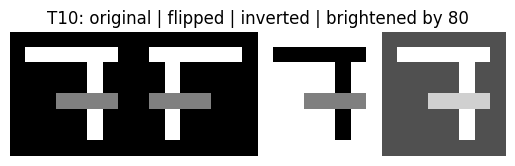

In [11]:
# T10: an image is an array
import matplotlib.pyplot as plt

# (a) draw the "7" from the lecture with slicing (white = 255, grey = 128)
img = np.zeros((8, 8), dtype=int)
img[1, 1:7] = 255        # top bar of the 7 (row 1, columns 1-6)
img[2:7, 5] = 255        # long stroke down column 5 (rows 2-6)
img[4, 3:7] = 128        # grey bar across the middle (row 4, columns 3-6)
print("T10a (the 7 on an 8 x 8 canvas):\n", img)

# (b) flip left-right (reverse the column order)
flipped = img[:, ::-1]
print("T10b (flipped left-right):\n", flipped)

# (c) invert (photographic negative)
inverted = 255 - img
print("T10c (inverted, 255 - img):\n", inverted)

# (d) crop rows 1-4 and columns 3-6 (stops are excluded, so the slices are 1:5 and 3:7)
cropped = img[1:5, 3:7]
print("T10d (crop of rows 1-4, columns 3-6), shape =", cropped.shape, "\n", cropped)

# (e) brighten by 80, capped at 255
brighter = np.clip(img + 80, 0, 255)
print("T10e (brightened by 80, capped at 255):\n", brighter)

# (f) shape, dtype and number of white pixels of the original image
print("T10f (shape):", img.shape)
print("T10f (dtype):", img.dtype)
print("T10f (white pixels, value 255):", (img == 255).sum(), "pixels")

# optional: original | flipped | inverted | brightened, side by side (fixed 0-255 scale)
plt.imshow(np.hstack([img, flipped, inverted, brighter]), cmap="gray", vmin=0, vmax=255)
plt.title("T10: original | flipped | inverted | brightened by 80")
plt.axis("off")
plt.show()


## Extra (not graded) · Sanity checks and bonus

In [12]:
# Sanity checks: independent re-computations that must agree with the answers above
assert np.isclose(share.sum(), 100)                          # T6b: shares add up to 100 %
assert np.isclose(quarter_total.sum(), rain[0].sum())      # T4d: quarters add up to the year
assert hall.sum() == 25 * 26 // 2                            # T5f: 1 + 2 + ... + 25
assert np.isclose(z.mean(), 0) and np.isclose(z.std(), 1)    # T9d: z-scores have mean 0 and std 1
assert counts.sum() == 10000                                 # T3c: every roll was counted once
print("Sanity checks: all passed")

# Bonus: a month counts only if EVERY city (every row) is above 30 degC -> all() along axis=0
all_hot = (tmax > 30).all(axis=0)
print("Bonus (months when all 5 cities were above 30 °C):", months[all_hot])


Sanity checks: all passed
Bonus (months when all 5 cities were above 30 °C): ['May' 'Jun' 'Jul' 'Aug' 'Sep']


## Task 11 · Reflection (Markdown cell)
Write 3–5 sentences: one finding from the census, one from the climate data and one from inflation that you did not know before. Then name one NumPy function that saved you from writing a loop, and what the loop would have looked like.

From the census I learned that Balochistan, not Punjab or Islamabad, is the fastest-growing unit (3.19 % per year), while AJK grows at only 1.15 % per year. In the climate data, Islamabad's monsoon rain (763 mm) is 1.7 times Lahore's (454 mm), and Quetta gets only 6.0 % of its yearly rain in the monsoon. In the inflation data, average inflation fell from 26.22 % to 4.87 %, which showed me that prices kept rising in FY2025, only more slowly. The NumPy function that saved me a loop was `argmax(axis=1)`: `months[tmax.argmax(axis=1)]` found the hottest month of all five cities in one line. Without it I would have needed a `for` loop over the cities that scans each row of 12 values, keeps a running maximum and its position, and then looks up the month name, about six lines instead of one.